# Unit 10: Customer Churn Prediction
## Logistic Regression Model for Telecommunications Customer Retention
### IN503 - Introduction to Machine Learning

**Student:** Danielle Holmes
**Date:** October 26, 2026
**Course:** IN503 - Introduction to Machine Learning

---

## Project Overview

Customer churn is expensive. Acquiring a replacement customer costs a telecommunications company substantially more than retaining an existing one, so the ability to identify who is likely to leave before they do determines whether a retention budget is spent usefully or wasted.

This project builds a logistic regression model on records for 7,043 customers, covering demographics, subscribed services, and account details. The target is whether a customer left the company. The work runs the full sequence from exploration through preprocessing, tuning, evaluation, coefficient interpretation, and a saved model with a working prediction function.

The goal is not only prediction. A model that scores well but explains nothing gives a retention team no direction, so this notebook treats the coefficients as a primary deliverable alongside the accuracy figures.

## Phase 1: Environment Setup

In [1]:
!pip install kagglehub

In [2]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             precision_score, recall_score, f1_score,
                             roc_curve, auc, roc_auc_score, ConfusionMatrixDisplay)
import joblib

# Set pandas display options for better readability
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

print("Libraries imported successfully.")

Libraries imported successfully.


## Phase 2: Data Acquisition and Exploration

In [3]:
# Download latest version
path = kagglehub.dataset_download("blastchar/telco-customer-churn")
filepath = path + '/WA_Fn-UseC_-Telco-Customer-Churn.csv'
print("Path to dataset files: ", filepath)

Using Colab cache for faster access to the 'telco-customer-churn' dataset.
Path to dataset files:  /kaggle/input/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv


In [4]:
# Load the dataset
df = pd.read_csv(filepath)

# Display the first 5 rows
print("First 5 rows of the dataset:")
print(df.head())

First 5 rows of the dataset:
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService     MultipleLines InternetService OnlineSecurity OnlineBackup DeviceProtection TechSupport StreamingTV StreamingMovies        Contract PaperlessBilling              PaymentMethod  MonthlyCharges TotalCharges Churn
0  7590-VHVEG  Female              0     Yes         No       1           No  No phone service             DSL             No          Yes               No          No          No              No  Month-to-month              Yes           Electronic check           29.85        29.85    No
1  5575-GNVDE    Male              0      No         No      34          Yes                No             DSL            Yes           No              Yes          No          No              No        One year               No               Mailed check           56.95       1889.5    No
2  3668-QPYBK    Male              0      No         No       2          Yes                No    

In [5]:
print("\nShape of the dataset: ")
print(df.shape)

print("\nDataFrame Info: ")
df.info()


Shape of the dataset: 
(7043, 21)

DataFrame Info: 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   ob

In [6]:
print("\nDescriptive statistics for numerical features:")
print(df.describe())


Descriptive statistics for numerical features:
       SeniorCitizen       tenure  MonthlyCharges
count    7043.000000  7043.000000     7043.000000
mean        0.162147    32.371149       64.761692
std         0.368612    24.559481       30.090047
min         0.000000     0.000000       18.250000
25%         0.000000     9.000000       35.500000
50%         0.000000    29.000000       70.350000
75%         0.000000    55.000000       89.850000
max         1.000000    72.000000      118.750000


In [7]:
print("\nMissing values before handling: ")
print(df.isnull().sum())

# Check for empty strings in TotalCharges
total_charges_missing = df[df['TotalCharges'] == ' '].shape[0]
print(f"\nNumber of empty strings in 'TotalCharges': {total_charges_missing}")


Missing values before handling: 
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Number of empty strings in 'TotalCharges': 11


In [8]:
# Replace empty strings with NaN and convert values to float
df['TotalCharges'] = df['TotalCharges'].replace(' ', np.nan).astype(float)

# Re-check for missing values
print("\nMissing values after handling 'TotalCharges' type: ")
print(df.isnull().sum())


Missing values after handling 'TotalCharges' type: 
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


In [9]:
# Inspect the rows that are missing TotalCharges before removing them
print("Tenure values for rows missing TotalCharges:")
print(df[df['TotalCharges'].isna()]['tenure'].value_counts())

Tenure values for rows missing TotalCharges:
tenure
0    11
Name: count, dtype: int64


In [10]:
# Drop rows with missing values (small number - 11 rows)
df.dropna(inplace=True)

# Verify cleanup
print("\nMissing values after dropping rows: ")
print(df.isnull().sum())
print(f"New dataset shape: {df.shape}")


Missing values after dropping rows: 
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64
New dataset shape: (7032, 21)


### Data Quality Findings

The most consequential problem in this dataset is invisible to a standard missing value check. `TotalCharges` loads as an object rather than a numeric column because a small number of rows contain a single space instead of a value, and `isnull()` counts a space as present data. Converting those spaces to `NaN` and casting the column to float exposes them.

The check above reveals what those rows represent. Every record missing `TotalCharges` has a tenure of zero, meaning these are brand new customers who have not yet been billed. The value is not missing through error, it is missing because nothing has been charged yet. Removing eleven records out of 7,043 is a reasonable choice at this scale, though it is worth recognizing that this quietly excludes the newest customers from the analysis, and new customers are precisely the group most at risk of leaving.

In [11]:
print("\nChurn distribution:")
print(df['Churn'].value_counts())

# Calculate percentages
churn_percentage = df['Churn'].value_counts(normalize=True) * 100
print("\nChurn percentage:")
print(churn_percentage)


Churn distribution:
Churn
No     5163
Yes    1869
Name: count, dtype: int64

Churn percentage:
Churn
No     73.421502
Yes    26.578498
Name: proportion, dtype: float64


### Target Variable Findings

The classes are imbalanced, with substantially more retained customers than churned ones. That imbalance sets the standard against which any accuracy figure has to be judged, because a model that predicted "no churn" for every customer would already score the majority class percentage while identifying not a single person at risk of leaving.

This is why the evaluation below reports precision, recall, and AUC alongside accuracy. For a retention use case, recall on the churn class is the metric that matters most, since a customer the model fails to flag is a customer nobody attempts to save.

### Exploratory Visualizations

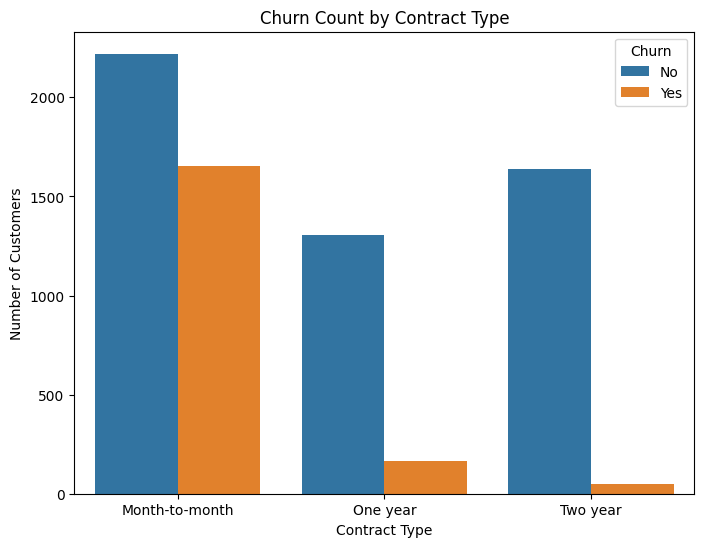

In [12]:
plt.figure(figsize=(8, 6))
sns.countplot(data=df, x='Contract', hue='Churn')
plt.title('Churn Count by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')
plt.show()

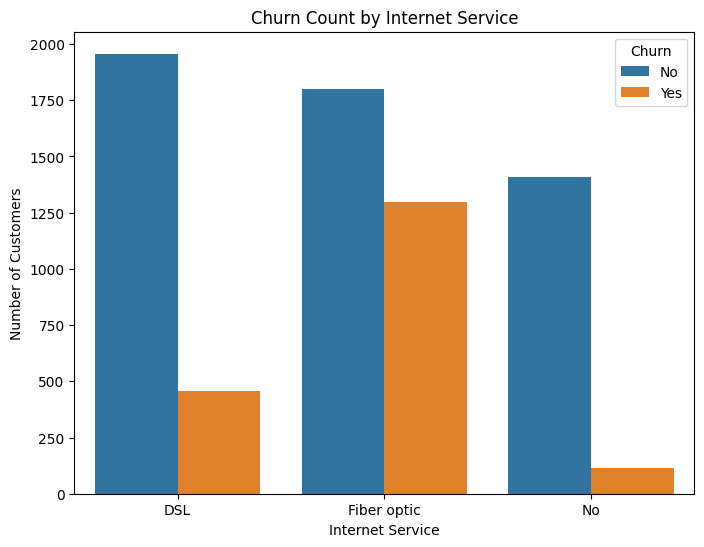

In [13]:
plt.figure(figsize=(8, 6))
sns.countplot(data=df, x='InternetService', hue='Churn')
plt.title('Churn Count by Internet Service')
plt.xlabel('Internet Service')
plt.ylabel('Number of Customers')
plt.show()

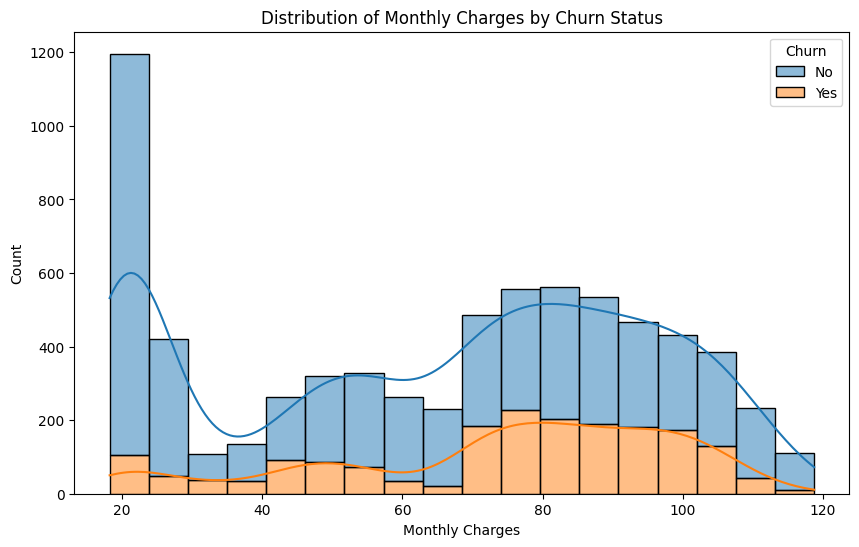

In [14]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='MonthlyCharges', hue='Churn', multiple='stack', kde=True)
plt.title('Distribution of Monthly Charges by Churn Status')
plt.xlabel('Monthly Charges')
plt.ylabel('Count')
plt.show()

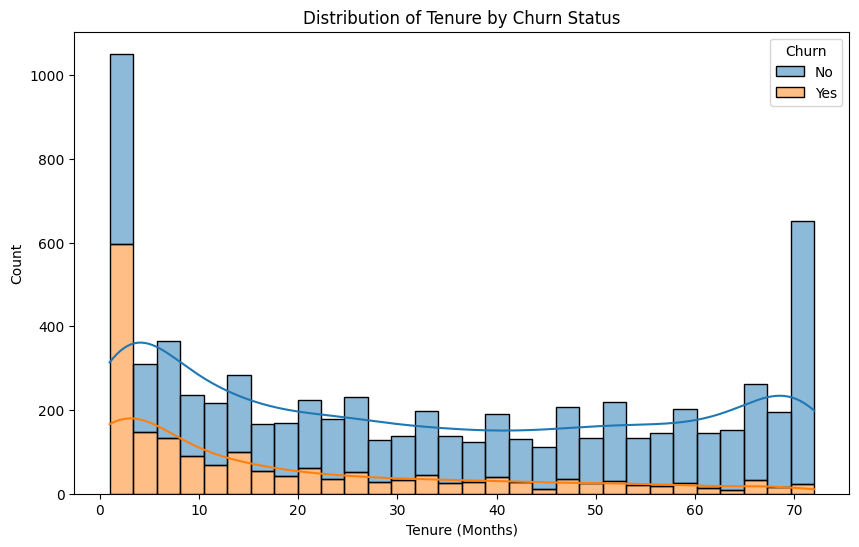

In [15]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='tenure', bins=30, kde=True, hue='Churn', multiple='stack')
plt.title('Distribution of Tenure by Churn Status')
plt.xlabel('Tenure (Months)')
plt.ylabel('Count')
plt.show()

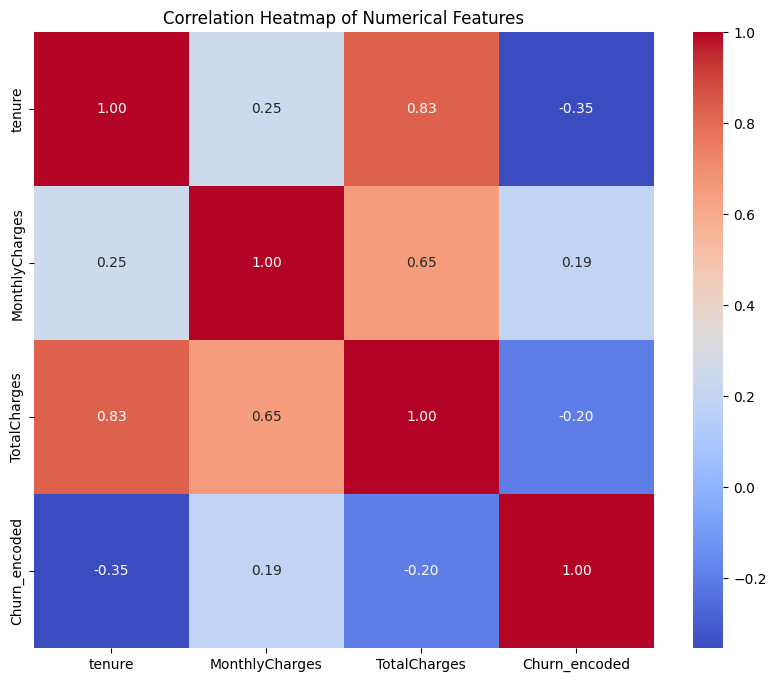

In [16]:
# Create temporary encoded churn variable
df['Churn_encoded'] = df['Churn'].map({'No': 0, 'Yes': 1})
numerical_df = df[['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn_encoded']]

plt.figure(figsize=(10, 8))
sns.heatmap(numerical_df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap of Numerical Features')
plt.show()

# Clean up temporary column
df.drop('Churn_encoded', axis=1, inplace=True)

### Business Insights from the Visualizations

**Contract type is the clearest signal.** Month-to-month customers churn at a far higher rate than those on one or two year agreements. The reading is straightforward, since a month-to-month customer faces no exit cost and can leave whenever a competitor makes a better offer, while a contracted customer has a reason to stay through a period of dissatisfaction. This points to the single most actionable lever available: moving customers onto longer agreements.

**Fiber optic customers churn more than DSL customers.** This is counterintuitive, because fiber is the premium product. The likely explanations are price, since fiber costs more, or unmet expectations around service reliability. Either way it deserves investigation, because the company is losing its highest-paying subscribers.

**Higher monthly charges track with churn.** The stacked distribution shows churned customers concentrated in the upper charge ranges. This overlaps with the fiber finding, since fiber subscribers pay more, and it raises the question of whether customers perceive the price as matching the value delivered.

**Tenure is strongly protective.** Churn concentrates heavily in the first months of the relationship and thins out considerably as tenure grows. Customers who make it past the early period tend to stay, which argues for concentrating retention effort in the onboarding window rather than spreading it evenly across the base.

**The correlation heatmap confirms the numeric relationships.** Tenure correlates negatively with churn while monthly charges correlate positively, and tenure and total charges correlate strongly with each other, which is expected since total charges accumulate over time. That last relationship is worth noting because it means the two features carry overlapping information rather than independent signal.

## Phase 3: Data Preprocessing and Feature Engineering

In [17]:
# Drop customerID as it's just an identifier
df.drop('customerID', axis=1, inplace=True)

print(f"Shape after dropping customerID: {df.shape}")

Shape after dropping customerID: (7032, 20)


In [18]:
# FEATURE ENGINEERING: count how many services each customer subscribes to
service_columns = ['PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
                   'OnlineBackup', 'DeviceProtection', 'TechSupport',
                   'StreamingTV', 'StreamingMovies']

# Values indicating the customer does NOT have that service
non_service_values = ['No', 'No internet service', 'No phone service']

df['TotalServices'] = df[service_columns].apply(
    lambda row: sum(value not in non_service_values for value in row), axis=1)

print("Distribution of TotalServices:")
print(df['TotalServices'].value_counts().sort_index())
print(f"\nMean services per customer: {df['TotalServices'].mean():.2f}")
print("\nChurn rate by number of services:")
print(df.groupby('TotalServices')['Churn'].apply(lambda s: (s == 'Yes').mean() * 100).round(2))

Distribution of TotalServices:
TotalServices
1    1260
2     857
3     846
4     965
5     921
6     906
7     674
8     395
9     208
Name: count, dtype: int64

Mean services per customer: 4.15

Churn rate by number of services:
TotalServices
1    10.95
2    31.04
3    44.92
4    36.48
5    31.38
6    25.61
7    22.55
8    12.41
9     5.29
Name: Churn, dtype: float64


### The Engineered Feature: TotalServices

`TotalServices` counts how many of the nine available services each customer subscribes to, ranging from phone and internet through security, backup, device protection, tech support, and streaming.

The reasoning is that bundling changes the nature of the relationship. A customer with one service is buying a commodity and can switch providers with little disruption. A customer with six services has woven the provider into their household, and leaving means replacing several things at once. That switching cost is not captured by any existing column, because the individual service fields each record a separate yes or no without expressing depth of engagement.

This feature is also directly actionable in a way that many engineered features are not. If subscription depth predicts retention, the retention team has a concrete intervention available, which is to offer an additional service rather than a discount. The churn rate breakdown printed above shows whether that relationship holds in this data.

In [19]:
# Define features (X) and target (y)
X = df.drop('Churn', axis=1)
y = df['Churn']

# Convert target to numerical format
y = y.map({'No': 0, 'Yes': 1})

print(f"Feature matrix shape: {X.shape}")
print(f"Target distribution:\n{y.value_counts()}")

Feature matrix shape: (7032, 20)
Target distribution:
Churn
0    5163
1    1869
Name: count, dtype: int64


In [20]:
# Identify categorical and numerical columns
categorical_cols = X.select_dtypes(include=['object']).columns
numerical_cols = X.select_dtypes(include=np.number).columns

print(f"\nCategorical columns: {list(categorical_cols)} ")
print(f"Numerical columns: {list(numerical_cols)} ")


Categorical columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod'] 
Numerical columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'TotalServices'] 


In [21]:
# Create transformers for preprocessing
numerical_transformer = StandardScaler()
categorical_transformer = OneHotEncoder(handle_unknown='ignore')

# Create preprocessor using ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_cols),
        ('cat', categorical_transformer, categorical_cols)
    ])

print("Preprocessor constructed.")

Preprocessor constructed.


### Preprocessing Rationale

**StandardScaler for numerical features.** Tenure runs from 1 to roughly 72 months while total charges reach into the thousands. Logistic regression with regularization penalizes coefficient magnitude, and without standardization that penalty would fall unevenly across features purely because of their units. Scaling puts every numeric feature on a common footing so the penalty reflects predictive contribution rather than measurement scale.

**One-hot encoding for categorical features.** Contract type, payment method, and internet service have no natural ordering. Assigning integers would tell the model that a two year contract is numerically twice a one year contract, which is not a meaningful statement. One-hot encoding gives each category its own binary column and avoids inventing that ranking. Setting `handle_unknown='ignore'` prevents a failure if a category appears in new data that was absent during training.

**ColumnTransformer inside a Pipeline.** Routing each column group to its own transformer and wrapping the result with the classifier means every preprocessing parameter, meaning the scaling values and the category lists, is learned from training data alone and then applied unchanged. This prevents leakage and, just as importantly for the deployment phase, means the saved model file carries its own preprocessing. New raw customer data can be passed straight in without reproducing any transformation steps by hand.

## Phase 4: Model Building and Training

In [22]:
# Split into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, \
random_state=42, stratify=y)

print(f"\nTraining set size: {X_train.shape[0]} rows")
print(f"Testing set size: {X_test.shape[0]} rows")
print(f"\nChurn rate in training set: {y_train.mean()*100:.2f}%")
print(f"Churn rate in test set: {y_test.mean()*100:.2f}%")


Training set size: 5625 rows
Testing set size: 1407 rows

Churn rate in training set: 26.58%
Churn rate in test set: 26.58%


In [23]:
# Create complete pipeline
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(solver='liblinear', random_state=42))
])

print("Pipeline created.")

Pipeline created.


### Why Logistic Regression Suits This Problem

The target has two outcomes, churned or retained, which is exactly what logistic regression is built for. Rather than predicting a class directly, it estimates the probability that a customer belongs to the churn class, and that probability is more useful to a retention team than a hard label. A team with budget to contact 500 customers can rank the base by risk score and work down the list, which a yes-or-no output would not support.

Interpretability is the stronger argument here. Each coefficient expresses how a feature shifts the log odds of churning, holding the others constant, and those coefficients can be converted into odds ratios that read as plain business statements. A retention strategy needs to know which levers to pull, and a model that reports month-to-month contracts as a specific multiplier on churn odds tells the team what to change. Gradient boosting would likely score somewhat higher on this data, but it would not hand the business a list of drivers in the same legible form.

The threshold is adjustable as well. The default cutoff of 0.5 can be lowered to catch more at-risk customers when the cost of missing one exceeds the cost of an unnecessary retention offer, which for churn is usually the case.

In [24]:
# Hyperparameter tuning on the regularization parameter C
param_grid = {'classifier__C': [0.001, 0.01, 0.1, 1, 10, 100]}

grid_search = GridSearchCV(
    model_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)

print("Running GridSearchCV on regularization parameter C...")
grid_search.fit(X_train, y_train)

print(f"\nBest C value: {grid_search.best_params_['classifier__C']}")
print(f"Best cross-validated ROC-AUC: {grid_search.best_score_:.4f}")

# Use the best estimator as the final model
model_pipeline = grid_search.best_estimator_
print("\nFinal model trained with best parameters.")

Running GridSearchCV on regularization parameter C...

Best C value: 100
Best cross-validated ROC-AUC: 0.8462

Final model trained with best parameters.


`C` is the inverse of regularization strength, so a small value applies heavy shrinkage and produces a simpler model with smaller coefficients, while a large value lets coefficients grow and fits the training data more closely. There is no way to reason out the right value in advance, so the search tests six values across five cross-validation folds inside the training set and selects the one that generalizes best.

Scoring is set to `roc_auc` rather than accuracy on purpose. Given the class imbalance, accuracy would reward a model that leans toward predicting no churn, while AUC measures how well the model ranks customers by risk across every possible threshold. Ranking quality is what a retention team actually uses.

## Phase 5: Model Evaluation and Interpretation

In [25]:
# Make predictions on test set
y_pred = model_pipeline.predict(X_test)
y_proba = model_pipeline.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred, target_names=['No Churn', 'Churn'])

print("\nModel Evaluation on Test Data:")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")
print("\nConfusion Matrix:")
print(conf_matrix)
print("\nClassification Report:")
print(class_report)


Model Evaluation on Test Data:
Accuracy:  0.7967
Precision: 0.6317
Recall:    0.5642
F1-Score:  0.5960

Confusion Matrix:
[[910 123]
 [163 211]]

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.85      0.88      0.86      1033
       Churn       0.63      0.56      0.60       374

    accuracy                           0.80      1407
   macro avg       0.74      0.72      0.73      1407
weighted avg       0.79      0.80      0.79      1407



In [26]:
# Compare against a baseline that always predicts "No Churn"
majority_baseline = (y_test == 0).mean()
print(f"Always-predict-No-Churn baseline accuracy: {majority_baseline:.4f}")
print(f"Model accuracy: {accuracy:.4f}")
print(f"Improvement over baseline: {(accuracy - majority_baseline)*100:.2f} percentage points")

Always-predict-No-Churn baseline accuracy: 0.7342
Model accuracy: 0.7967
Improvement over baseline: 6.25 percentage points


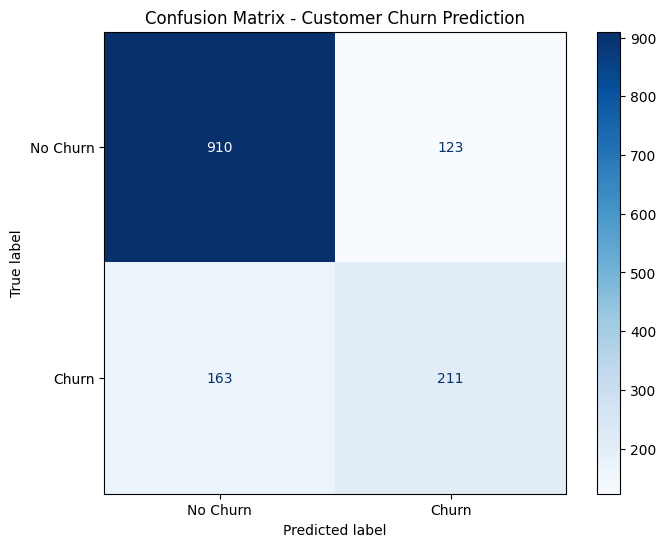

In [27]:
# Confusion matrix visualization
fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix,
                              display_labels=['No Churn', 'Churn'])
disp.plot(cmap='Blues', ax=ax, values_format='d')
plt.title('Confusion Matrix - Customer Churn Prediction')
plt.grid(False)
plt.show()

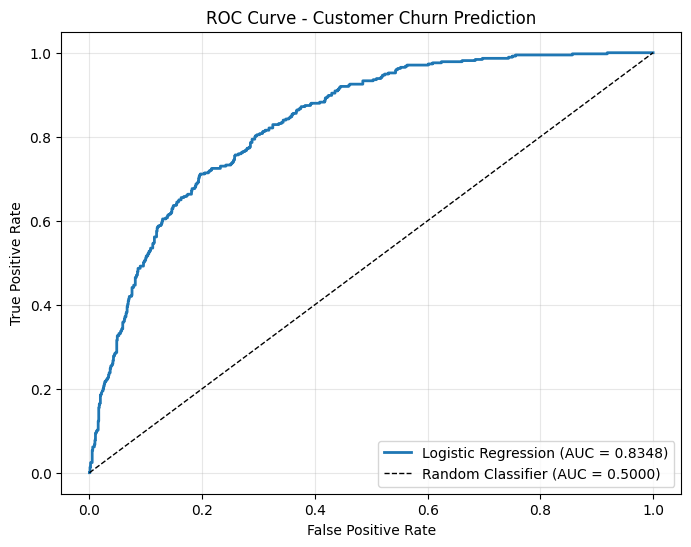

ROC-AUC Score: 0.8348


In [28]:
# ROC curve and AUC
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, linewidth=2, label=f'Logistic Regression (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random Classifier (AUC = 0.5000)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Customer Churn Prediction')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.show()

print(f"ROC-AUC Score: {roc_auc_score(y_test, y_proba):.4f}")

### Reading the Evaluation Output

The model reached 79.67% accuracy, but the comparison cell shows why that number needs context. Always predicting no churn scores 73.42%, so the model adds just 6.25 percentage points. Framed as errors it looks better: the error rate drops from 26.58% to 20.33%, a reduction of about 23.5%.

Precision and recall tell the operational story. Of 334 customers the model flagged, 211 actually churned, so precision is 63.17% and roughly a third of retention spend would go to people who were staying anyway. Recall is 56.42%, meaning the model caught 211 of 374 actual churners and missed 163 of them. Those 163 are customers who left with no intervention attempted, and for a retention program that is the number that matters most.

ROC-AUC of 0.8348 is the more encouraging figure. The model ranks customers by risk far better than accuracy alone suggests, which is exactly what a prioritized call list needs. Cross-validated AUC was 0.8462 against 0.8348 on the test set, a gap of 0.0114, small enough to indicate the tuning did not overfit the training folds.

The recall figure argues for lowering the decision threshold below 0.5. If a retention offer costs a fraction of a lost customer, catching more churners is worth accepting more false alarms.

In [29]:
# Extract trained components
log_reg = model_pipeline.named_steps['classifier']
fitted_preprocessor = model_pipeline.named_steps['preprocessor']

# Get feature names after one-hot encoding
ohe_feature_names = fitted_preprocessor.named_transformers_['cat'].get_feature_names_out(categorical_cols)
feature_names = list(numerical_cols) + list(ohe_feature_names)

# Create coefficients DataFrame
coefficients = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': log_reg.coef_[0]
})

# Convert to odds ratios for business interpretation
coefficients['Odds_Ratio'] = np.exp(coefficients['Coefficient'])

# Sort by absolute coefficient value
coefficients['Abs_Coefficient'] = coefficients['Coefficient'].abs()
coefficients.sort_values(by='Abs_Coefficient', ascending=False, inplace=True)

print("\nTop 10 most impactful features on Churn:")
print(coefficients.head(10).to_string(index=False))


Top 10 most impactful features on Churn:
                             Feature  Coefficient  Odds_Ratio  Abs_Coefficient
                      MonthlyCharges    -2.276285    0.102665         2.276285
                              tenure    -1.411645    0.243742         1.411645
         InternetService_Fiber optic     1.348172    3.850380         1.348172
                 InternetService_DSL    -1.288726    0.275622         1.288726
                       TotalServices     0.901007    2.462081         0.901007
                   Contract_Two year    -0.832687    0.434879         0.832687
                        TotalCharges     0.705274    2.024400         0.705274
             Contract_Month-to-month     0.582262    1.790084         0.582262
     TechSupport_No internet service    -0.489688    0.612818         0.489688
DeviceProtection_No internet service    -0.489688    0.612818         0.489688


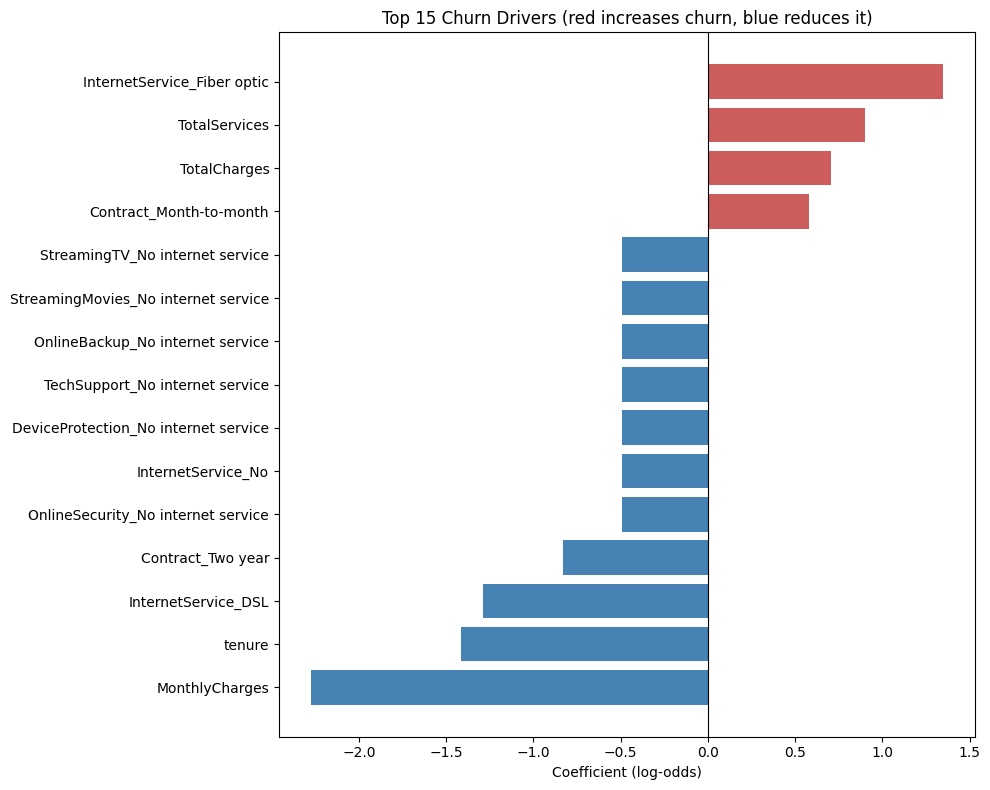

In [30]:
# Visualize the top 15 coefficients
top_features = coefficients.head(15).sort_values('Coefficient')

plt.figure(figsize=(10, 8))
colors = ['steelblue' if c < 0 else 'indianred' for c in top_features['Coefficient']]
plt.barh(top_features['Feature'], top_features['Coefficient'], color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Top 15 Churn Drivers (red increases churn, blue reduces it)')
plt.xlabel('Coefficient (log-odds)')
plt.tight_layout()
plt.show()

### Interpreting the Coefficients in Business Terms

A positive coefficient raises the odds of churning, a negative one lowers them, and the odds ratio column converts each into a multiplier. Two results here run opposite to what the exploratory analysis suggested.

MonthlyCharges is negative (odds ratio 0.103), even though the histogram showed higher charges tracking with churn. These are not in conflict. The raw relationship is driven by fiber optic customers, who both pay more and leave more. Once the model accounts for internet service type and service count separately, the leftover effect of price flips: among customers with the same product, paying more is associated with staying, not leaving.

Fiber optic is the strongest positive driver at 3.85× the odds of churning, while DSL runs at 0.276×. That is a wide gap between two internet products in the same company and points at a service quality or expectations problem rather than a pricing one.

TotalServices came in positive at 2.46× per standard deviation, which refutes the hypothesis behind it. The feature was built on the idea that bundling raises switching cost and should protect against churn. The data says the reverse: holding other factors constant, customers with more services leave more often. A plausible reading is that each added service is another thing that can disappoint, and more touchpoints mean more chances to become dissatisfied. The feature ranked fifth of all predictors, so it is clearly informative. Its direction is just the opposite of what was expected.

Contract type behaves as predicted. Two year contracts cut the odds to 0.435× while month-to-month raises them to 1.79×, and tenure is strongly protective at 0.244×.

## Phase 6: Model Deployment Simulation

In [31]:
# Save the complete pipeline
model_filename = 'customer_churn_model.pkl'
joblib.dump(model_pipeline, model_filename)
print(f"\nTrained model pipeline saved as '{model_filename}'")


Trained model pipeline saved as 'customer_churn_model.pkl'


In [32]:
# Load the saved model
loaded_model = joblib.load('customer_churn_model.pkl')
print("Model pipeline loaded successfully.")


def predict_churn(customer_data, model=loaded_model, threshold=0.5):
    """Predict churn for one customer.

    Args:
        customer_data: dict of raw customer attributes (same columns used in training).
        model: fitted pipeline that handles its own preprocessing.
        threshold: probability cutoff for flagging a customer as a churn risk.

    Returns:
        dict with the prediction label, churn probability, and a risk band.
    """
    customer_df = pd.DataFrame([customer_data])
    probability = model.predict_proba(customer_df)[0][1]
    prediction = 'Yes' if probability >= threshold else 'No'

    if probability >= 0.70:
        risk = 'High'
    elif probability >= 0.40:
        risk = 'Medium'
    else:
        risk = 'Low'

    return {'churn_prediction': prediction,
            'churn_probability': round(float(probability), 4),
            'risk_level': risk}

print("Prediction function defined.")

Model pipeline loaded successfully.
Prediction function defined.


In [33]:
# Helper to build a full customer record with sensible defaults
def build_customer(**overrides):
    base = {
        'gender': 'Male', 'SeniorCitizen': 0, 'Partner': 'No', 'Dependents': 'No',
        'tenure': 12, 'PhoneService': 'Yes', 'MultipleLines': 'No',
        'InternetService': 'DSL', 'OnlineSecurity': 'No', 'OnlineBackup': 'No',
        'DeviceProtection': 'No', 'TechSupport': 'No', 'StreamingTV': 'No',
        'StreamingMovies': 'No', 'Contract': 'One year', 'PaperlessBilling': 'No',
        'PaymentMethod': 'Mailed check', 'MonthlyCharges': 55.0, 'TotalCharges': 660.0
    }
    base.update(overrides)

    # Recompute the engineered feature so it stays consistent with training
    base['TotalServices'] = sum(
        base[c] not in ['No', 'No internet service', 'No phone service']
        for c in service_columns)
    return base


# EXAMPLE 1: High-risk profile
customer_1 = build_customer(
    tenure=1, InternetService='Fiber optic', Contract='Month-to-month',
    PaperlessBilling='Yes', PaymentMethod='Electronic check',
    MonthlyCharges=75.75, TotalCharges=75.75)

# EXAMPLE 2: Low-risk profile
customer_2 = build_customer(
    Partner='Yes', Dependents='Yes', tenure=68, MultipleLines='Yes',
    InternetService='DSL', OnlineSecurity='Yes', OnlineBackup='Yes',
    DeviceProtection='Yes', TechSupport='Yes', Contract='Two year',
    PaymentMethod='Bank transfer (automatic)',
    MonthlyCharges=84.50, TotalCharges=5746.00)

# EXAMPLE 3: Mixed profile
customer_3 = build_customer(
    tenure=20, InternetService='Fiber optic', StreamingTV='Yes',
    StreamingMovies='Yes', Contract='Month-to-month', PaperlessBilling='Yes',
    PaymentMethod='Credit card (automatic)',
    MonthlyCharges=95.20, TotalCharges=1904.00)

for label, customer in [('1 (new fiber, month-to-month)', customer_1),
                        ('2 (long tenure, two-year contract, bundled)', customer_2),
                        ('3 (mid tenure, fiber, month-to-month)', customer_3)]:
    result = predict_churn(customer)
    print(f"\nCustomer {label}")
    print(f"  Tenure: {customer['tenure']} months | Contract: {customer['Contract']} "
          f"| Services: {customer['TotalServices']}")
    print(f"  Predicted churn: {result['churn_prediction']} "
          f"| Probability: {result['churn_probability']} "
          f"| Risk: {result['risk_level']}")


Customer 1 (new fiber, month-to-month)
  Tenure: 1 months | Contract: Month-to-month | Services: 2
  Predicted churn: Yes | Probability: 0.5972 | Risk: Medium

Customer 2 (long tenure, two-year contract, bundled)
  Tenure: 68 months | Contract: Two year | Services: 7
  Predicted churn: No | Probability: 0.002 | Risk: Low

Customer 3 (mid tenure, fiber, month-to-month)
  Tenure: 20 months | Contract: Month-to-month | Services: 4
  Predicted churn: No | Probability: 0.497 | Risk: Medium


### Deployment Considerations

**What the saved file contains.** The pickled object is the entire pipeline, not just the fitted classifier, so scaling parameters and one-hot category mappings travel with the model. A production system passes raw customer records straight in without reimplementing any preprocessing, which removes the most common source of training and serving mismatch, where preprocessing drifts apart between the two environments.

**How this would run in practice.** The natural deployment is a scheduled batch job rather than a live service. A nightly or weekly run scores the active customer base, writes probabilities back to the CRM, and delivers the retention team a ranked call list. A REST endpoint would suit a service representative seeing a risk score during a live call, but batch scoring covers the primary use case at far less operational cost.

**The threshold is a business decision, not a technical one.** The function accepts a threshold argument because 0.5 is only the default, not the right answer. If a retention offer costs \$50 and a lost customer costs \$500, flagging more customers is worth it even though more of those flags will be wrong, and the threshold should move down accordingly.

**Monitoring matters more than the initial accuracy.** Customer behavior shifts as competitors change pricing and as the company changes its own offers, so a model trained on last year's base will degrade. Performance needs tracking over time against outcomes that arrive weeks later, with retraining scheduled rather than waiting for someone to notice the model has stopped working. The engineered `TotalServices` feature has to be recomputed identically in production, which is why the helper above derives it from the service columns rather than accepting it as an input.

## Summary and Business Recommendations

**Model performance.** The model reached 79.67% accuracy against a 73.42% do-nothing baseline, a gain of 6.25 percentage points, with ROC-AUC of 0.8348. The weak point is recall at 56.42%: the model missed 163 of 374 actual churners. As a ranking tool for prioritizing outreach it works well. As a hard yes-or-no decision at the default threshold it lets too many at-risk customers through, which argues for lowering the cutoff.

**Primary churn drivers.** Fiber optic service carries 3.85 times the odds of churning, the largest effect in the model. Month-to-month contracts run at 1.79 times, while two year contracts cut the odds to 0.435. Tenure is strongly protective, and churn concentrates heavily in the early months.

**Recommendations.** Investigate fiber optic first. It is the strongest driver, and the negative coefficient on monthly charges says the issue is the product rather than the price, so a discount would treat the wrong problem. Focus retention effort on the first months of the relationship, where churn concentrates. Test contract conversion incentives for month-to-month customers, offering added value rather than price cuts. Use the probability output to rank the base and work down the list, and lower the threshold below 0.5 given how many churners the default cutoff misses.

**Limitations.** The engineered TotalServices feature was influential but pointed the opposite direction from its hypothesis, so bundling should not be assumed protective without further testing. Tuning selected C at the top of its grid, which permits large coefficients on correlated features and makes the individual numeric magnitudes unreliable. The eleven records dropped during cleaning were all zero-tenure customers, the group most exposed to churn. And these coefficients describe association rather than causation, so a strong predictor is not automatically a lever that changes behavior.

In [34]:
from google.colab import files
files.download('customer_churn_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>